<a href="https://colab.research.google.com/github/taissa-arruda/prog_estat/blob/main/Resolu%C3%A7%C3%A3o_labs/Lab9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Exercício 1**

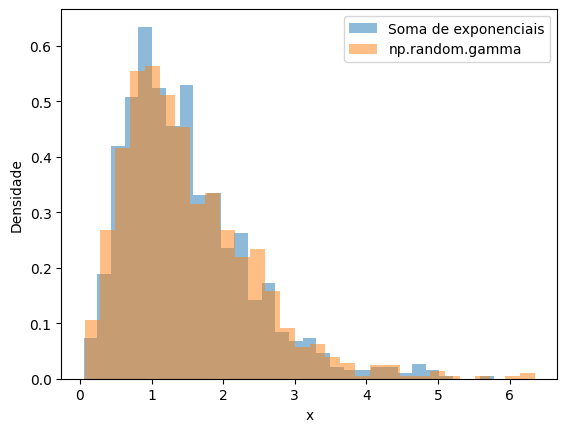

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n = 1000
k = 3
lam = 2

amostra = []
for i in range(n):
    soma = 0
    for j in range(k):
        soma = soma + np.random.exponential(1 / lam)
    amostra.append(soma)

amostra_numpy = np.random.gamma(k, 1 / lam, n)

plt.hist(amostra, bins=30, density=True, alpha=0.5, label="Soma de exponenciais")
plt.hist(amostra_numpy, bins=30, density=True, alpha=0.5, label="np.random.gamma")
plt.xlabel("x")
plt.ylabel("Densidade")
plt.legend()
plt.show()

**Exercício 2**

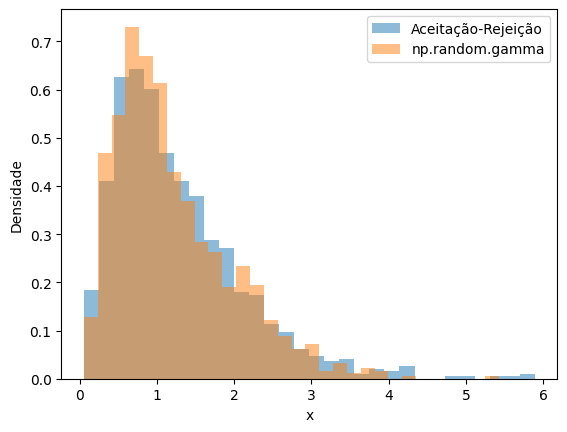

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def gamma_ar(alfa, lam, n):
    amostra = []
    for i in range(n):
        aceitou = False
        while aceitou == False:
            y = np.random.exponential(alfa / lam)
            u = np.random.uniform(0, 1)
            t = lam * y / alfa
            if u <= (t * np.exp(1 - t))**(alfa - 1):
                amostra.append(y)
                aceitou = True
    return amostra

n = 1000
alfa = 2.5
lam = 2

amostra = gamma_ar(alfa, lam, n)
amostra_numpy = np.random.gamma(alfa, 1 / lam, n)

plt.hist(amostra, bins=30, density=True, alpha=0.5, label="Aceitação-Rejeição")
plt.hist(amostra_numpy, bins=30, density=True, alpha=0.5, label="np.random.gamma")
plt.xlabel("x")
plt.ylabel("Densidade")
plt.legend()
plt.show()

**Exercício 3**

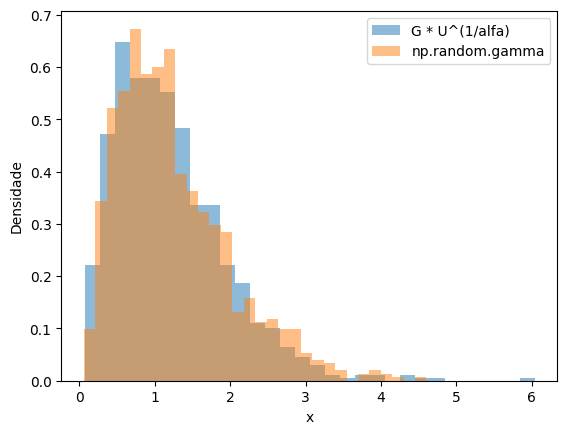

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n = 1000
alfa = 2.5
lam = 2

G = gamma_ar(alfa + 1, lam, n)

amostra = []
for i in range(n):
    u = np.random.uniform(0, 1)
    amostra.append(G[i] * u**(1 / alfa))

amostra_numpy = np.random.gamma(alfa, 1 / lam, n)

plt.hist(amostra, bins=30, density=True, alpha=0.5, label="G * U^(1/alfa)")
plt.hist(amostra_numpy, bins=30, density=True, alpha=0.5, label="np.random.gamma")
plt.xlabel("x")
plt.ylabel("Densidade")
plt.legend()
plt.show()

**Exercício 4**

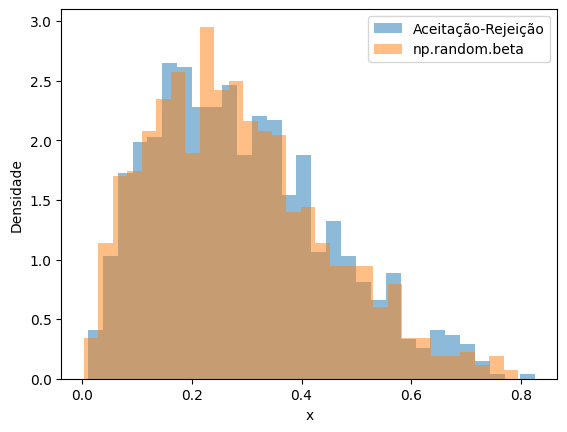

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n = 1000
alfa = 2
beta = 5

def f(x):
    return x**(alfa - 1) * (1 - x)**(beta - 1)

malha = np.linspace(0, 1, 10000)
M = np.max(f(malha))

amostra = []
for i in range(n):
    aceitou = False
    while aceitou == False:
        y = np.random.uniform(0, 1)
        u = np.random.uniform(0, 1)
        if u <= f(y) / M:
            amostra.append(y)
            aceitou = True

amostra_numpy = np.random.beta(alfa, beta, n)

plt.hist(amostra, bins=30, density=True, alpha=0.5, label="Aceitação-Rejeição")
plt.hist(amostra_numpy, bins=30, density=True, alpha=0.5, label="np.random.beta")
plt.xlabel("x")
plt.ylabel("Densidade")
plt.legend()
plt.show()

**Exercício 5**

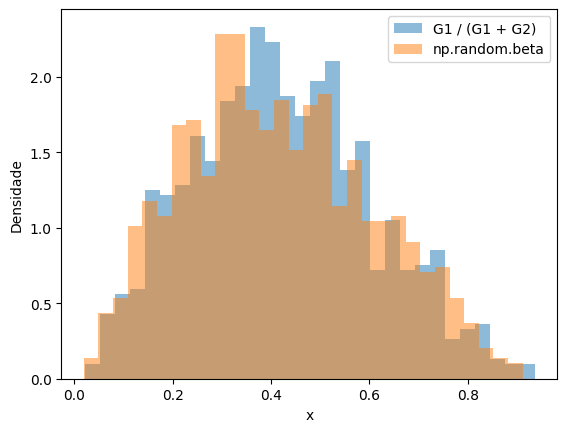

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n = 1000
alfa = 2.5
beta = 3.5

G1 = gamma_ar(alfa, 1, n)
G2 = gamma_ar(beta, 1, n)

amostra = []
for i in range(n):
    amostra.append(G1[i] / (G1[i] + G2[i]))

amostra_numpy = np.random.beta(alfa, beta, n)

plt.hist(amostra, bins=30, density=True, alpha=0.5, label="G1 / (G1 + G2)")
plt.hist(amostra_numpy, bins=30, density=True, alpha=0.5, label="np.random.beta")
plt.xlabel("x")
plt.ylabel("Densidade")
plt.legend()
plt.show()